# CSCI461 – Assignment 1: Dockerized Data, Text Analysis and Machine Learning
## Dataset: SMS Spam Collection (UCI #228)

**Pipeline:** Dockerfile → custom image → container → JupyterLab → data cleaning → sampling → text analysis → TF‑IDF → classification + K‑Means → persistent outputs (`output/`, bind‑mounted to the host).

| Section | Content |
|---|---|
| 0 | Environment check (proves the notebook runs inside the container) |
| 4 | Data understanding, missing values & duplicates, `loc`/`iloc`, transformations, sampling, correlation |
| 5 | Text cleaning, tokenisation, word frequencies, spam vs ham comparison, insights |
| 6 | Supervised TF‑IDF classification (2 classifiers + tuned n‑gram model = bonus) and K‑Means clustering |
| 7 | Saved outputs checklist |

Run with **Kernel → Restart Kernel and Run All Cells**. Every random step uses `random_state=42`, so results are reproducible.

## 0. Setup and environment check

In [1]:
import os, re, sys, html, string, platform, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, Normalizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, silhouette_score,
                             adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Project root: works whether Jupyter starts in bd-a1/ or in bd-a1/notebook/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "dataset.csv"
OUTPUT_DIR = ROOT / "output"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(ROOT)}")

in_docker = Path("/.dockerenv").exists() or os.environ.get("JUPYTER_DOCKER_STACKS_FOLDER") is not None \
            or os.environ.get("NB_USER") == "jovyan"
print("Running inside Docker container:", in_docker)
print("Hostname      :", platform.node())
print("Python        :", sys.version.split()[0])
print("pandas        :", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("Project root  :", ROOT)
print("Dataset path  :", DATA_PATH, "| exists:", DATA_PATH.exists())

Running inside Docker container: False
Hostname      : vm
Python        : 3.13.18
pandas        : 3.0.5 | numpy: 2.5.3 | scikit-learn: 1.9.1
Project root  : /home/claude/bd-a1
Dataset path  : /home/claude/bd-a1/data/dataset.csv | exists: True


## 4. Data Analysis and Preprocessing
### 4.1 Dataset understanding
The original UCI file (`SMSSpamCollection`) is tab‑separated with no header. It was converted once on the host into `data/dataset.csv` with two columns, `label` and `message` (see README for the exact command).

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")
df = df_raw.copy()
display(df.head(10))

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"
5,spam,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv"
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030


In [3]:
print("Shape  :", df.shape)
print("Columns:", list(df.columns))
print("\nData types:\n", df.dtypes, sep="")
print()
df.info()

Shape  : (5574, 2)
Columns: ['label', 'message']

Data types:
label      str
message    str
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5574 non-null   str  
 1   message  5574 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


In [4]:
display(df.describe(include="all"))
print("\nClass distribution:")
display(pd.DataFrame({"count": df["label"].value_counts(),
                      "percent": df["label"].value_counts(normalize=True).mul(100).round(2)}))

,label,message
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30



Class distribution:


,count,percent
label,,
ham,4827,86.6
spam,747,13.4


**What one row represents:** one SMS text message received on a mobile phone, together with a human‑assigned label saying whether it is legitimate (`ham`) or unsolicited advertising/scam (`spam`).

| Column type | Column(s) | Notes |
|---|---|---|
| **Text** | `message` | Raw SMS body (free text, slang, abbreviations, numbers, URLs) |
| **Label / category** | `label` | Binary target: `ham` (≈86.6 %) vs `spam` (≈13.4 %) → **imbalanced** |
| **Numerical** | *none in the raw file* | Numerical columns are **engineered** from the text in 4.4 (character count, word count, digit count, …) and used for correlation and normalisation |

`describe()` already shows that the most frequent message ("Sorry, I'll call later") occurs many times, a first hint of duplicates.

### 4.2 Missing values and duplicates

In [5]:
print("Missing values per column:")
display(df.isna().sum().to_frame("missing"))

empty_msgs = df["message"].fillna("").str.strip().eq("").sum()
print("Empty / whitespace-only messages:", empty_msgs)

dup_rows = df.duplicated().sum()
dup_msgs = df["message"].duplicated().sum()
conflicts = (df.groupby("message")["label"].nunique() > 1).sum()
print("Exact duplicate rows (label + message):", dup_rows)
print("Duplicate message texts              :", dup_msgs)
print("Same text with different labels      :", conflicts)

print("\nDuplicate rows by class:")
display(df[df.duplicated()]["label"].value_counts().to_frame("duplicates"))
print("Most repeated messages:")
display(df["message"].value_counts().head(5).to_frame("times"))

Missing values per column:


,missing
label,0
message,0


Empty / whitespace-only messages: 0
Exact duplicate rows (label + message): 403
Duplicate message texts              : 403
Same text with different labels      : 0

Duplicate rows by class:


,duplicates
label,
ham,309
spam,94


Most repeated messages:


,times
message,
"Sorry, I'll call later",30
I cant pick the phone right now. Pls send a message,12
Ok...,10
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!,4
"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.",4


**Treatment and justification**

* **Missing values:** there are none (and no empty strings). A defensive `fillna("")` is still applied in the text‑cleaning function so the pipeline cannot break on future data.
* **Duplicates:** the exact duplicates are **removed** (keeping the first occurrence) because
  1. repeated spam templates and chain messages would be **over‑counted** in word frequencies and group statistics;
  2. if the same message appears in both the training and the test split, the classifier is tested on text it has **already seen** (data leakage), which inflates accuracy;
  3. no duplicate text carries conflicting labels, so dropping copies loses no information.

In [6]:
shape_before = df.shape
df = df.drop_duplicates(keep="first").reset_index(drop=True)
shape_after = df.shape
print(f"Shape before cleaning: {shape_before}")
print(f"Shape after cleaning : {shape_after}  ({shape_before[0] - shape_after[0]} rows removed)")
display(pd.DataFrame({"before": df_raw["label"].value_counts(), "after": df["label"].value_counts()}))

Shape before cleaning: (5574, 2)
Shape after cleaning : (5171, 2)  (403 rows removed)


,before,after
label,,
ham,4827,4518
spam,747,653


### 4.3 Selection with `loc` and `iloc`
* `loc` selects by **label / boolean condition**.
* `iloc` selects by **integer position**; `np.r_` concatenates several position ranges into one indexer.

In [7]:
# loc: meaningful conditional selection -> spam messages that mention "free" and are longer than 120 characters
mask = (df["label"] == "spam") & df["message"].str.contains(r"\bfree\b", case=False) & (df["message"].str.len() > 120)
free_spam = df.loc[mask, ["label", "message"]]
print(f"Long spam messages containing 'free': {len(free_spam)} rows")
display(free_spam.head(5))

Long spam messages containing 'free': 128 rows


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C www.dbuk.net LCCLTD POBOX 4403LDNW1A7RW18"
42,spam,07732584351 - Rodger Burns - MSG = We tried to call you re your reply to our sms for a free nokia mobile + free camcorder. Please call now 08000930705 for delivery tomorrow
56,spam,"Congrats! 1 year special cinema pass for 2 is yours. call 09061209465 now! C Suprman V, Matrix3, StarWars3, etc all 4 FREE! bx420-ip4-5we. 150pm. Dont miss out!"


In [8]:
# iloc: plain positional selection -> rows 10-14, both columns
display(df.iloc[10:15, 0:2])

# iloc + np.r_: first 3 rows, rows 2000-2002 and the last 3 rows in a single selection
display(df.iloc[np.r_[0:3, 2000:2003, -3:0], :])

,label,message
10,ham,"I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today."
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info"
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C www.dbuk.net LCCLTD POBOX 4403LDNW1A7RW18"
13,ham,I've been searching for the right words to thank you for this breather. I promise i wont take your help for granted and will fulfil my promise. You have been wonderful and a blessing at all times.
14,ham,I HAVE A DATE ON SUNDAY WITH WILL!!


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
2000,ham,Must come later.. I normally bathe him in da afternoon mah..
2001,ham,"Trust me. Even if isn't there, its there."
2002,ham,Hey hun-onbus goin 2 meet him. He wants 2go out 4a meal but I donyt feel like it cuz have 2 get last bus home!But hes sweet latelyxxx
5168,ham,"Pity, * was in mood for that. So...any other suggestions?"
5169,ham,The guy did some bitching but I acted like i'd be interested in buying something else next week and he gave it to us for free
5170,ham,Rofl. Its true to its name


### 4.4 Transformations and feature creation
Five transformations are applied:

| # | Type | Result |
|---|---|---|
| T1 | **Type conversion** | `label` → `category`, `message` → `string` |
| T2 | **Encoding** | `label_num`: ham = 0, spam = 1 (needed by models and correlation) |
| T3 | **Feature creation** | numerical text features: `char_count`, `word_count`, `unique_word_count`, `avg_word_length`, `digit_count`, `uppercase_ratio`, `punctuation_count`, `exclamation_count`, `has_url`, `has_long_number` |
| T4 | **Binning** | `length_bin` based on the 160‑character limit of a single SMS |
| T5 | **Normalisation** | Min–Max scaling of the numerical features into [0, 1] (`*_norm` columns) |

In [9]:
# T1 - type conversion
print("Before:", df.dtypes.to_dict())
df["label"] = df["label"].astype("category")
df["message"] = df["message"].astype("string")
print("After :", df.dtypes.to_dict())

# T2 - label encoding
df["label_num"] = df["label"].map({"ham": 0, "spam": 1}).astype(int)
display(df[["label", "label_num"]].drop_duplicates())

Before: {'label': <StringDtype(storage='python', na_value=nan)>, 'message': <StringDtype(storage='python', na_value=nan)>}
After : {'label': CategoricalDtype(categories=['ham', 'spam'], ordered=False, categories_dtype=str), 'message': <StringDtype(storage='python', na_value=<NA>)>}


,label,label_num
0,ham,0
2,spam,1


In [10]:
# T3 - numerical feature creation from the ORIGINAL message (HTML entities such as &lt; decoded first)
raw_text = df["message"].fillna("").astype(str).map(html.unescape)
words = raw_text.str.split()

df["char_count"]        = raw_text.str.len()
df["word_count"]        = words.str.len()
df["unique_word_count"] = words.map(lambda w: len({x.lower() for x in w}))
df["avg_word_length"]   = words.map(lambda w: np.mean([len(x) for x in w]) if w else 0.0).round(3)
df["digit_count"]       = raw_text.str.count(r"\d")
df["uppercase_ratio"]   = (raw_text.str.count(r"[A-Z]") / df["char_count"].clip(lower=1)).round(4)
df["punctuation_count"] = raw_text.map(lambda t: sum(ch in string.punctuation for ch in t))
df["exclamation_count"] = raw_text.str.count("!")
df["has_url"]           = raw_text.str.contains(r"https?://|www\.|\.com\b|\.co\.uk\b", case=False).astype(int)
df["has_long_number"]   = raw_text.str.contains(r"\d{5,}").astype(int)   # phone / short-code numbers

NUM_FEATURES = ["char_count", "word_count", "unique_word_count", "avg_word_length",
                "digit_count", "uppercase_ratio", "punctuation_count", "exclamation_count"]
display(df[["label"] + NUM_FEATURES].head())

,label,char_count,word_count,unique_word_count,avg_word_length,digit_count,uppercase_ratio,punctuation_count,exclamation_count
0,ham,111,20,20,4.600,0,0.0270,9,0
1,ham,29,6,6,4.000,0,0.0690,6,0
2,spam,155,28,24,4.571,25,0.0645,6,0
3,ham,49,11,10,3.545,0,0.0408,6,0
4,ham,61,13,12,3.769,0,0.0328,2,0


In [11]:
# T4 - binning: 160 characters is the length limit of one SMS
bins   = [0, 50, 100, 160, np.inf]
labels = ["short (<=50)", "medium (51-100)", "long (101-160)", "multi-part (>160)"]
df["length_bin"] = pd.cut(df["char_count"], bins=bins, labels=labels)

display(pd.crosstab(df["length_bin"], df["label"], margins=True))
display(pd.crosstab(df["length_bin"], df["label"], normalize="index").mul(100).round(1)
          .rename(columns=lambda c: f"% {c}"))

label,ham,spam,All
length_bin,,,
short (<=50),2171,20,2191
medium (51-100),1351,53,1404
long (101-160),817,527,1344
multi-part (>160),179,53,232
All,4518,653,5171


label,% ham,% spam
length_bin,,
short (<=50),99.1,0.9
medium (51-100),96.2,3.8
long (101-160),60.8,39.2
multi-part (>160),77.2,22.8


In [12]:
# T5 - Min-Max normalisation of the numerical features
scaler = MinMaxScaler()
norm_cols = [f"{c}_norm" for c in NUM_FEATURES]
df[norm_cols] = scaler.fit_transform(df[NUM_FEATURES])

comparison = pd.concat({"original": df[NUM_FEATURES[:4]].describe().loc[["min", "max", "mean"]],
                        "normalised": df[norm_cols[:4]].describe().loc[["min", "max", "mean"]]}, axis=1)
display(comparison.round(3))

original                                                   normalised                                                            
     char_count word_count unique_word_count avg_word_length char_count_norm word_count_norm unique_word_count_norm avg_word_length_norm
min       2.000      1.000             1.000           1.500           0.000           0.000                  0.000                0.000
max     910.000    171.000           100.000          49.000           1.000           1.000                  1.000                1.000
mean     78.955     15.434            14.266           4.227           0.085           0.085                  0.134                0.057

Saved figure -> output/figures/length_distribution.png


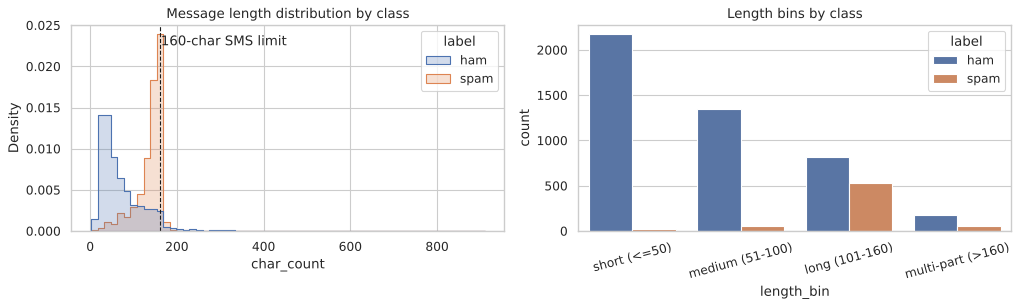

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="char_count", hue="label", bins=60, stat="density", common_norm=False,
             element="step", ax=axes[0])
axes[0].axvline(160, color="k", ls="--", lw=1); axes[0].text(163, axes[0].get_ylim()[1]*0.9, "160-char SMS limit")
axes[0].set_title("Message length distribution by class")
sns.countplot(data=df, x="length_bin", hue="label", ax=axes[1])
axes[1].set_title("Length bins by class"); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); save_fig(fig, "length_distribution.png"); plt.show()

### 4.5 Sampling: simple random, stratified and cluster
Each sample is ≈20 % of the cleaned data.

* **Simple random sampling (SRS):** every message has the same chance of being chosen, independently.
* **Stratified sampling:** the data is split into strata by `label`, and 20 % is drawn **from each stratum** so the class proportions are preserved exactly.
* **Cluster sampling:** the data is divided into **clusters** (here: consecutive blocks of 100 messages, like batches received by a telecom server), then **whole clusters** are randomly selected and all their messages kept. The README of the dataset states the messages are *not chronologically sorted*, so blocks are reasonable clusters.

In [14]:
FRAC = 0.20
srs = df.sample(frac=FRAC, random_state=RANDOM_STATE)

stratified = df.groupby("label", group_keys=False, observed=True).sample(frac=FRAC, random_state=RANDOM_STATE)

CLUSTER_SIZE = 100
df["cluster_block"] = np.arange(len(df)) // CLUSTER_SIZE
n_blocks = df["cluster_block"].nunique()
rng = np.random.default_rng(RANDOM_STATE)
chosen_blocks = rng.choice(n_blocks, size=round(FRAC * n_blocks), replace=False)
cluster_sample = df[df["cluster_block"].isin(chosen_blocks)]
print(f"{n_blocks} clusters of {CLUSTER_SIZE} messages; selected clusters: {sorted(chosen_blocks.tolist())}")

def dist(d):
    vc = d["label"].value_counts()
    return pd.Series({"n": len(d), "ham": vc.get("ham", 0), "spam": vc.get("spam", 0),
                      "% ham": round(100 * vc.get("ham", 0) / len(d), 2),
                      "% spam": round(100 * vc.get("spam", 0) / len(d), 2)})

sampling_table = pd.DataFrame({"Original (clean)": dist(df), "Simple random": dist(srs),
                               "Stratified": dist(stratified), "Cluster": dist(cluster_sample)}).T
display(sampling_table)

52 clusters of 100 messages; selected clusters: [3, 4, 10, 20, 29, 34, 41, 46, 49, 51]


,n,ham,spam,% ham,% spam
Original (clean),5171.0,4518.0,653.0,87.37,12.63
Simple random,1034.0,897.0,137.0,86.75,13.25
Stratified,1035.0,904.0,131.0,87.34,12.66
Cluster,971.0,866.0,105.0,89.19,10.81


True % spam in cleaned data: 12.628


,mean,std,min,max
Simple random,12.630,0.907,10.542,14.990
Stratified,12.657,0.000,12.657,12.657
Cluster,12.534,0.965,10.100,15.400


Saved figure -> output/figures/sampling_comparison.png


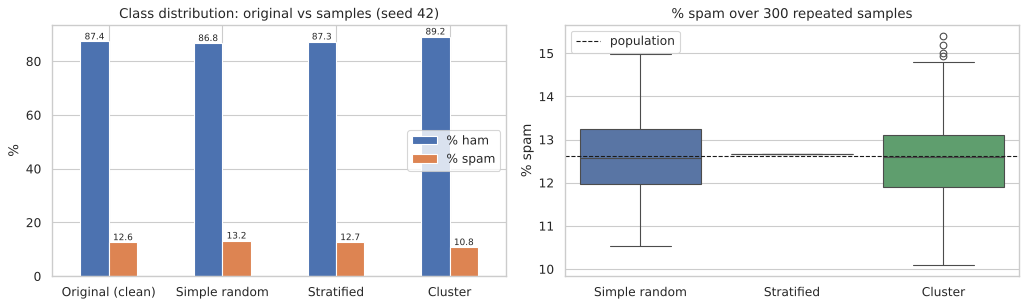

In [15]:
# How stable is each method? Repeat each 300 times with different seeds and look at the spread of % spam.
def spam_pct(d): return 100 * (d["label"] == "spam").mean()
reps = {"Simple random": [], "Stratified": [], "Cluster": []}
for seed in range(300):
    reps["Simple random"].append(spam_pct(df.sample(frac=FRAC, random_state=seed)))
    reps["Stratified"].append(spam_pct(df.groupby("label", group_keys=False, observed=True).sample(frac=FRAC, random_state=seed)))
    blocks = np.random.default_rng(seed).choice(n_blocks, size=round(FRAC * n_blocks), replace=False)
    reps["Cluster"].append(spam_pct(df[df["cluster_block"].isin(blocks)]))
rep_df = pd.DataFrame(reps)
stability = rep_df.agg(["mean", "std", "min", "max"]).T.round(3)
print(f"True % spam in cleaned data: {spam_pct(df):.3f}")
display(stability)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_tbl = sampling_table[["% ham", "% spam"]]
plot_tbl.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0)
axes[0].set_title("Class distribution: original vs samples (seed 42)"); axes[0].set_ylabel("%")
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.1f", fontsize=8)
sns.boxplot(data=rep_df, ax=axes[1]); axes[1].axhline(spam_pct(df), color="k", ls="--", lw=1, label="population")
axes[1].set_title("% spam over 300 repeated samples"); axes[1].set_ylabel("% spam"); axes[1].legend()
plt.tight_layout(); save_fig(fig, "sampling_comparison.png"); plt.show()

**Comparison of the three methods**

* **Stratified** reproduces the original class ratio (almost) exactly every time; its spread across 300 repetitions is practically zero. It is the right choice when a minority class (spam) must be represented faithfully, which is why the train/test split in Section 6 is stratified.
* **Simple random** is unbiased on average, but any single sample can drift by roughly ±1 percentage point in % spam, purely by chance.
* **Cluster** sampling is the cheapest to collect (take whole batches), but it has the **largest variance**: messages inside a block are not perfectly mixed, so choosing a few blocks can over‑ or under‑represent spam. The sample size is also fixed by the cluster sizes rather than chosen exactly.

### 4.6 Correlation of numerical text features

Saved figure -> output/figures/correlation_heatmap.png


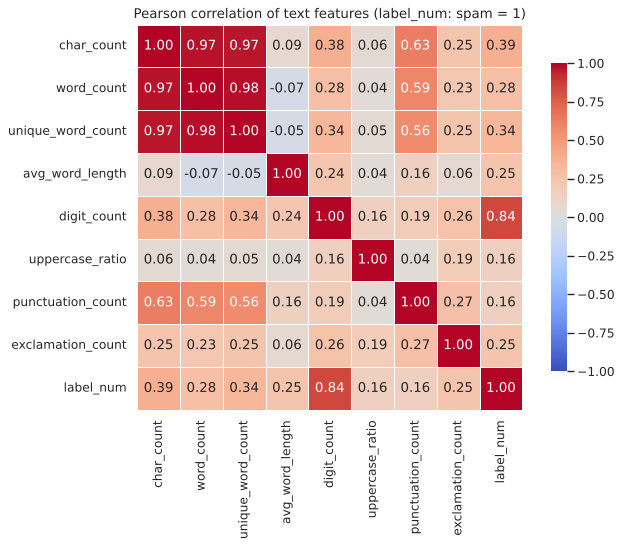

Strongest relationships:


,feature_1,feature_2,r,|r|
11,word_count,unique_word_count,0.981,0.981
1,char_count,word_count,0.974,0.974
2,char_count,unique_word_count,0.966,0.966
44,digit_count,label_num,0.837,0.837
6,char_count,punctuation_count,0.625,0.625
15,word_count,punctuation_count,0.592,0.592


Weakest relationships:


,feature_1,feature_2,r,|r|
14,word_count,uppercase_ratio,0.037,0.037
51,uppercase_ratio,punctuation_count,0.039,0.039
32,avg_word_length,uppercase_ratio,0.044,0.044
23,unique_word_count,uppercase_ratio,0.047,0.047


Correlation of each feature with spam (label_num):


,r with spam
digit_count,0.837
char_count,0.386
unique_word_count,0.337
word_count,0.284
exclamation_count,0.255
avg_word_length,0.250
punctuation_count,0.159
uppercase_ratio,0.159


In [16]:
corr_cols = NUM_FEATURES + ["label_num"]
corr = df[corr_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Pearson correlation of text features (label_num: spam = 1)")
plt.tight_layout(); save_fig(fig, "correlation_heatmap.png"); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("r").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["|r|"] = pairs["r"].abs()
print("Strongest relationships:"); display(pairs.sort_values("|r|", ascending=False).head(6).round(3))
print("Weakest relationships:");   display(pairs.sort_values("|r|").head(4).round(3))
print("Correlation of each feature with spam (label_num):")
display(corr["label_num"].drop("label_num").sort_values(ascending=False).round(3).to_frame("r with spam"))

**Interpretation** *(values from the heatmap above)*

* **Very strong (r ≈ 0.97–0.98):** `word_count`, `unique_word_count` and `char_count` move almost perfectly together. They are mechanically linked (more words means more characters), so they carry nearly the same information. Using all three in a linear model would be redundant (multicollinearity).
* **Strong link with the target:** `digit_count` has **r = 0.84 with spam**, by far the highest. Spam is full of phone numbers, prices and short codes.
* **Moderate:** `char_count` with spam (r ≈ 0.39): spam is longer on average, but many ham messages are long too. `char_count` with `punctuation_count` (r ≈ 0.63): longer texts simply contain more punctuation.
* **Weak / none:** `uppercase_ratio` is almost uncorrelated with the length features (|r| ≈ 0.04) and only weakly with spam (r ≈ 0.16). Shouting in capitals happens in both classes ("I HAVE A DATE ON SUNDAY WITH WILL!!"). `exclamation_count` is weakly related to spam (r ≈ 0.26).


**Why correlation does not imply causation:** a correlation only says two variables move together. For example, `digit_count` is strongly associated with spam, but adding digits to a message does not *make* it spam. Both are driven by a third factor: commercial senders who include phone numbers, prices and short codes. Correlation also only measures *linear* association, can be inflated by outliers and by features that are mechanically derived from each other (word count is part of character count), and says nothing about direction. Establishing cause requires controlled experiments or causal reasoning, not a coefficient.